---
title: SARIMA Models
---

We will discuss ARIMA models, seasonal ARMA models, multiplicative seasonal ARMA models and SARIMA models. 

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings("ignore") # this suppresses convergence warnings from the ARIMA function

## ARIMA models

We continue with the GDP dataset from the last few lectures (US GDP from FRED, https://fred.stlouisfed.org/series/GDP, in billions of dollars, quarterly, seasonally adjusted, not adjusted for inflation). As before, we work with the logarithms of the data, and we split the data into training and test sets with the last 50 quarters as the test set.

  observation_date      GDP
0       1947-01-01  243.164
1       1947-04-01  245.968
2       1947-07-01  249.585
3       1947-10-01  259.745
4       1948-01-01  265.742


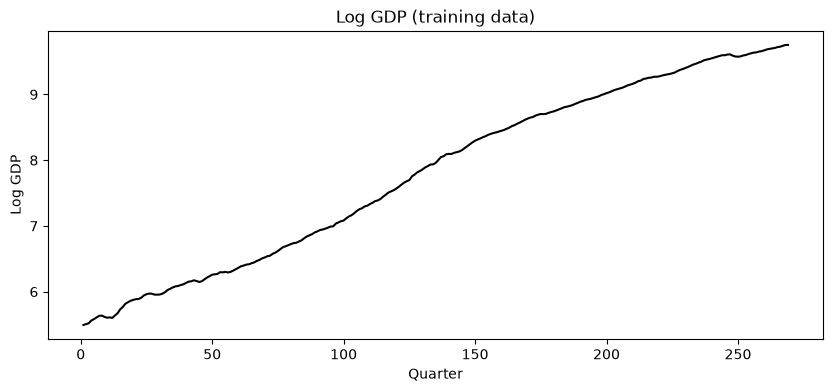

In [110]:
gdp = pd.read_csv("GDP_29Oct2026.csv")
print(gdp.head())
y = gdp['GDP'].to_numpy()
n = len(y)
tme = np.arange(1, n+1)
n_test = 50
n_train = n - n_test
y_train = y[:n_train]
y_test = y[n_train:]
tme_train = tme[:n_train]
tme_test = tme[n_train:]
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

plt.figure(figsize = (10, 4))
plt.plot(tme_train, ylog_train, color = 'black')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('Log GDP (training data)')
plt.show()

We will apply the ARIMA($p$, $d$, $q$) model for this data with $d = 1$. This means that ARMA($p$, $q$) model is used for the differenced data $y_t - y_{t-1}$. Why is it sensible to work with differences for the log GDP data?

Why difference log GDP? The models we have already fit suggest it. Every AR model that we fit to log GDP had a root of the AR polynomial at (or extremely close to) 1: AR(1) gave $\hat{\phi}_1 = 0.9984$, AR(4) had a root of modulus 1.0016, and ARMA(1, 2) gave $\hat{\phi}_1 = 0.998$ and needed the option `enforce_stationarity = False`.

To see what this means, take the AR(1) model $y_t = \phi_0 + \phi_1 y_{t-1} + \epsilon_t$. When $|\phi_1| < 1$, the series is pulled back toward a fixed mean level after every shock. When $\phi_1 = 1$, there is no such pull, and the model becomes
$$y_t - y_{t-1} = \phi_0 + \epsilon_t.$$
So the fitted AR(1) with $\hat{\phi}_1 \approx 1$ is really saying that the *differences* $\nabla y_t = y_t - y_{t-1}$ of log GDP are simple (a constant plus noise), while log GDP itself just accumulates these differences. The same holds for higher orders: if the AR polynomial has a root at 1, then it factors as $\phi(z) = (1 - z)\psi(z)$, and the model $\phi(B) y_t = \epsilon_t$ can be rewritten as $\psi(B) \nabla y_t = \epsilon_t$, which is an AR model of one lower order for the differences. In other words, our fits are telling us to model $\nabla y_t$ instead of $y_t$.

The simplest example is the random walk $y_t = y_{t-1} + \epsilon_t$, whose differences $\nabla y_t = \epsilon_t$ are white noise. Below is a simulated random walk together with its sample ACF, and the sample ACF of its differences. The sample ACF of the random walk decays very slowly, which looks like strong and complicated dependence, yet after differencing nothing is left but white noise. We shall see subsequently that the sample ACF of the log-GDP series has a similar structure. 

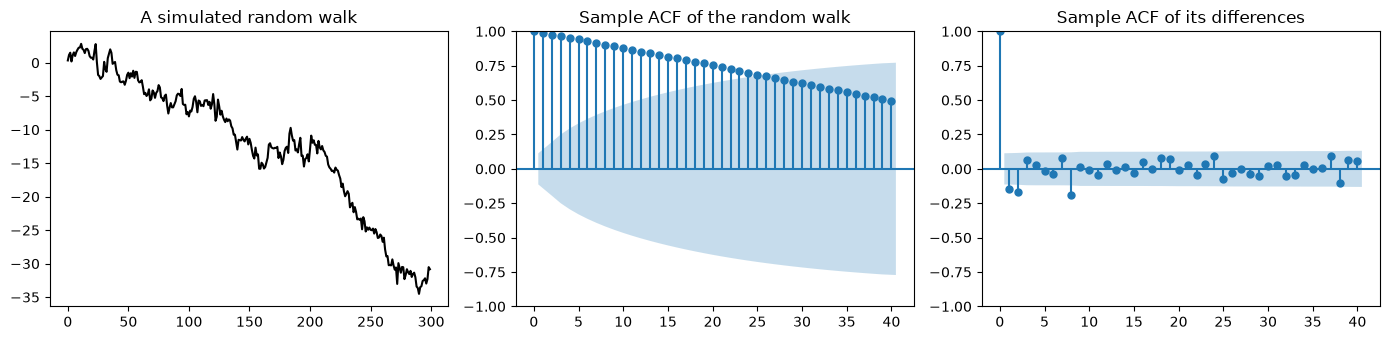

In [111]:
#A simulated random walk and its sample ACF and the sample ACF of its differences

rng = np.random.default_rng(1)
eps = rng.normal(size = 300)
rw = np.cumsum(eps) # random walk: y_t = eps_1 + ... + eps_t

fig, ax = plt.subplots(1, 3, figsize = (14, 3.5))
ax[0].plot(rw, color = 'black')
ax[0].set_title('A simulated random walk')
plot_acf(rw, lags = 40, ax = ax[1])
ax[1].set_title('Sample ACF of the random walk')
plot_acf(np.diff(rw), lags = 40, ax = ax[2])
ax[2].set_title('Sample ACF of its differences')
plt.tight_layout()
plt.show()

The sample ACF of log GDP has exactly this slowly decaying shape, as can be seen below. 

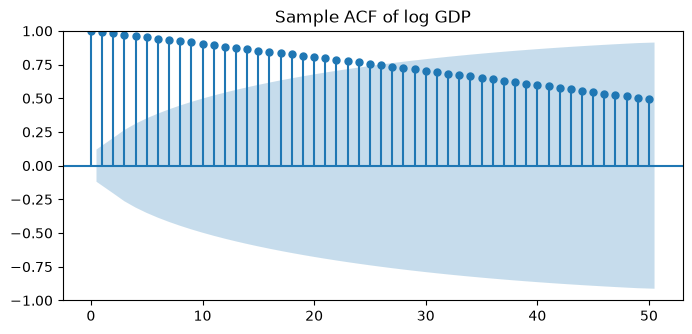

Sample ACF of log GDP at lags 1, 2, 3, 10, 20: [0.991 0.981 0.971 0.904 0.806]


In [112]:
h_max = 50
fig, ax = plt.subplots(figsize = (8, 3.5))
plot_acf(ylog_train, lags = h_max, ax = ax)
ax.set_title("Sample ACF of log GDP")
plt.show()
print("Sample ACF of log GDP at lags 1, 2, 3, 10, 20:", np.round(acf(ylog_train, nlags = 20)[[1, 2, 3, 10, 20]], 3))

We therefore work with the differences of log GDP: $\nabla \log y_t = \log y_t - \log y_{t-1}$. Note that these differences are the quarterly growth rates of GDP. One can check that the differenced series fluctuates around a fixed level (about 0.016, i.e., 1.6% growth per quarter), and its sample ACF decays quickly.

Mean quarterly growth rate in the training data: 0.0159


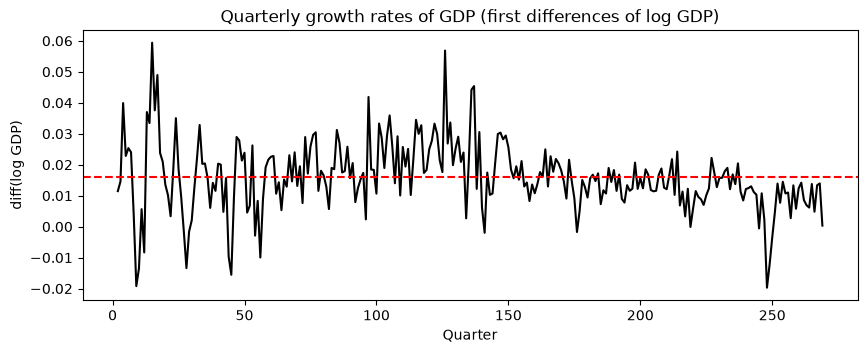

In [113]:
ylogdiff_train = np.diff(ylog_train) # quarterly growth rates
print("Mean quarterly growth rate in the training data:", np.round(np.mean(ylogdiff_train), 4))

plt.figure(figsize = (10, 3.5))
plt.plot(tme_train[1:], ylogdiff_train, color = 'black')
plt.axhline(np.mean(ylogdiff_train), color = 'red', linestyle = '--')
plt.xlabel('Quarter')
plt.ylabel('diff(log GDP)')
plt.title('Quarterly growth rates of GDP (first differences of log GDP)')
plt.show()

We will fit an AR or MA or ARMA model to the growth rates. 

Below are the sample ACF and the sample PACF of the growth rates. The sample PACF at lag $h$ is $\hat{\phi}_{h,h}$, the coefficient of the last lag when an AR($h$) model is fit to the data; this is the plot that we used in Lecture 19 to choose the AR order (the option `method = 'ols'` computes $\hat{\phi}_{h, h}$ by least squares, as in Lecture 19).

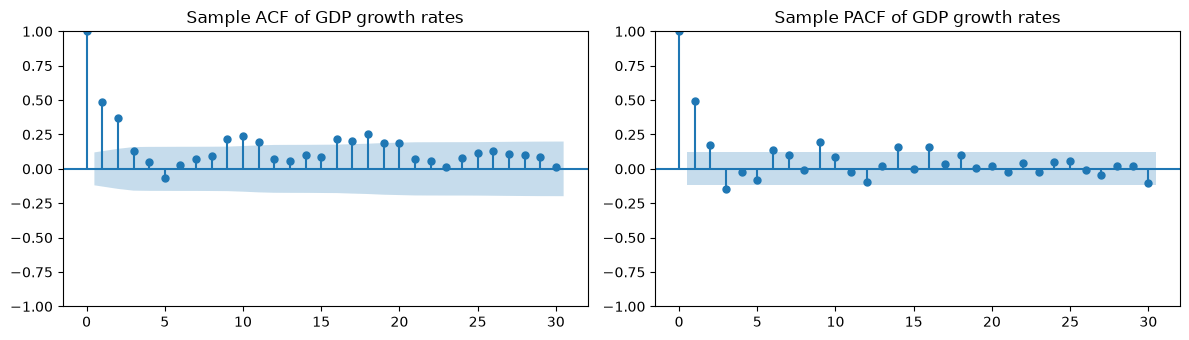

Sample ACF  at lags 1-6: [ 0.49   0.369  0.128  0.051 -0.07   0.024]
Sample PACF at lags 1-6: [ 0.493  0.17  -0.147 -0.022 -0.083  0.135]


In [114]:
h_max = 30
fig, ax = plt.subplots(1, 2, figsize = (12, 3.5))
plot_acf(ylogdiff_train, lags = h_max, ax = ax[0])
ax[0].set_title("Sample ACF of GDP growth rates")
plot_pacf(ylogdiff_train, lags = h_max, ax = ax[1], method = 'ols')
ax[1].set_title("Sample PACF of GDP growth rates")
plt.tight_layout()
plt.show()
print("Sample ACF  at lags 1-6:", np.round(acf(ylogdiff_train, nlags = 6)[1:], 3))
print("Sample PACF at lags 1-6:", np.round(pacf(ylogdiff_train, nlags = 6, method = 'ols')[1:], 3))

The sample PACF cuts off after lag 2 or 3. This is the signature of an AR(2) or AR(3) model for the growth rates, i.e., of ARIMA(2, 1, 0) or ARIMA(3, 1, 0) for log GDP.

## Fitting ARIMA($p$, 1, $q$) with the ARIMA function

ARIMA($p, d, q$) models are fit by `ARIMA(y, order = (p, d, q))`. With $d = 1$, the function fits an ARMA($p, q$) model to the first differences of `y`, and its forecasts are forecasts of `y` itself (the differencing is undone automatically). One important detail: when $d \geq 1$, the ARIMA function does not include a constant by default (we noticed this for the varve data in the last lecture). The growth rates of GDP have a clearly nonzero mean (1.6% per quarter), so we must include the constant. This is done with the option `trend = 't'` (a constant in the differenced series is the same thing as a linear trend in the original series, hence the letter `t`).

We first fit ARIMA(3, 1, 0), which is the model suggested by the ACF/PACF plots.

In [116]:
arimamod = ARIMA(ylog_train, order = (3, 1, 0), trend = 't').fit()
print(arimamod.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  269
Model:                 ARIMA(3, 1, 0)   Log Likelihood                 869.099
Date:                Wed, 11 Nov 2026   AIC                          -1728.198
Time:                        20:04:47   BIC                          -1710.243
Sample:                             0   HQIC                         -1720.986
                                - 269                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0158      0.001     12.847      0.000       0.013       0.018
ar.L1          0.4344      0.051      8.476      0.000       0.334       0.535
ar.L2          0.2303      0.053      4.352      0.0

The coefficients `ar.L1`, `ar.L2`, `ar.L3` are $\phi_1, \phi_2, \phi_3$ and `sigma2` is $\sigma^2$. The coefficient labeled `x1` (0.0158) is the mean $\mu$ of the growth rates: as mentioned in the notes, the ARIMA function always parametrizes the constant as the mean $\mu$ of the (differenced) series rather than as the intercept $\phi_0$ of the AR equation. The two are related by $\phi_0 = \mu (1 - \phi_1 - \phi_2 - \phi_3)$. One can check, as follows, that the fitted ARMA model is stable (by looking at the moduli of the roots of the AR polynomial); so the predictions eventually approach $\hat{\mu}$.

In [118]:
params = arimamod.params
mu_hat = params[0]
phi = params[1:4]
print("Estimated mean growth rate per quarter (x1):", np.round(mu_hat, 4))
print("Sample mean of the growth rates:            ", np.round(np.mean(ylogdiff_train), 4))
print("Implied intercept phi_0 = mu (1 - phi_1 - phi_2 - phi_3):", np.round(mu_hat * (1 - np.sum(phi)), 4))
print("Moduli of the AR roots:", np.round(np.abs(arimamod.arroots), 3))

Estimated mean growth rate per quarter (x1): 0.0158
Sample mean of the growth rates:             0.0159
Implied intercept phi_0 = mu (1 - phi_1 - phi_2 - phi_3): 0.0077
Moduli of the AR roots: [1.883 1.882 1.882]


To choose $p$ and $q$, we can use go over all values of $p, q$ in a given range and then find the model for which the AIC or BIC is the smallest. 

## Choosing $p$ and $q$ by AIC/BIC (with $d = 1$ fixed)

We now fit all ARIMA($p$, 1, $q$) models with $p, q \leq 3$ (all with the constant) and compare their AIC and BIC values. Note that $d$ is held fixed at 1 throughout: AIC/BIC values are only comparable across models fit to the same data (see the notes).

In [119]:
pmax, qmax = 3, 3
results = []
for p in range(pmax + 1):
    for q in range(qmax + 1):
        model = ARIMA(ylog_train, order = (p, 1, q), trend = 't').fit()
        results.append({'p': p, 'd': 1, 'q': q, 'AIC': model.aic, 'BIC': model.bic})
results_df = pd.DataFrame(results)

print("Models sorted by AIC (best first):")
print(results_df.sort_values('AIC').head(6).to_string(index = False))
print("\nModels sorted by BIC (best first):")
print(results_df.sort_values('BIC').head(6).to_string(index = False))

Models sorted by AIC (best first):
 p  d  q          AIC          BIC
 3  1  0 -1728.197800 -1710.242865
 1  1  2 -1727.057695 -1709.102760
 3  1  1 -1725.972831 -1704.426909
 2  1  1 -1725.528846 -1707.573911
 0  1  3 -1725.389785 -1707.434850
 1  1  3 -1725.366501 -1703.820580

Models sorted by BIC (best first):
 p  d  q          AIC          BIC
 3  1  0 -1728.197800 -1710.242865
 2  1  0 -1724.270559 -1709.906611
 1  1  2 -1727.057695 -1709.102760
 1  1  0 -1718.502329 -1707.729368
 2  1  1 -1725.528846 -1707.573911
 0  1  3 -1725.389785 -1707.434850


Both AIC and BIC pick ARIMA(3, 1, 0), with ARIMA(2, 1, 0) a close second by BIC and ARIMA(1, 1, 2) a close second by AIC. The models near the top of both lists have similar forecasts, so the choice among them is not critical. We go with ARIMA(3, 1, 0).

**Why AIC/BIC cannot be used to choose $d$.** The log-likelihood of an ARIMA model with $d = 1$ is the log-likelihood of the *differenced* data. The following check shows this: fitting ARIMA(0, 1, 2) with a constant to log GDP gives exactly the same log-likelihood as fitting MA(2) with a constant to the differenced log GDP.

In [120]:
mod_a = ARIMA(ylog_train, order = (0, 1, 2), trend = 't').fit()   # ARIMA(0, 1, 2) with drift, fit to log GDP
mod_b = ARIMA(ylogdiff_train, order = (0, 0, 2), trend = 'c').fit() # MA(2) with a constant, fit to the growth rates
print("Log-likelihood of ARIMA(0, 1, 2) fit to log GDP:        ", np.round(mod_a.llf, 3), " (number of observations:", mod_a.nobs, ")")
print("Log-likelihood of MA(2) fit to the differenced log GDP: ", np.round(mod_b.llf, 3), " (number of observations:", mod_b.nobs, ")")

Log-likelihood of ARIMA(0, 1, 2) fit to log GDP:         864.644  (number of observations: 269 )
Log-likelihood of MA(2) fit to the differenced log GDP:  864.644  (number of observations: 268 )


A model with $d = 0$, on the other hand, has the log-likelihood of the undifferenced data (e.g., the ARMA(1, 2) model of the last lecture had log-likelihood 861.0 for the 269 values of log GDP). Likelihoods of different datasets are not comparable, and hence neither are their AIC or BIC values. In the last lecture's notebook, we looped over $d = 0, 1, 2$ as well as $p$ and $q$; the comparisons across different values of $d$ in that loop should be taken with a grain of salt, while the comparisons for a fixed $d$ are fine. The value of $d$ should be chosen by looking at the data, as we did above.

## Checking the residuals

If the model is adequate, the residuals should look like i.i.d noise. We plot the residuals and their sample ACF. For these models, the first few residuals are not well-defined. For example, for AR($p$) the residuals are $y_t - \hat{\phi}_0 - \sum_{j=1}^p \hat{\phi}_j y_{t-j}$, which requires $y_{t-1}, \dots, y_{t-p}$ and so is only defined for $t > p$. The `.resid` attribute nevertheless returns a value for every $t$, but the initial values are not meaningful as residuals in this sense. We therefore drop the first few residuals before plotting.

In [126]:
print(len(arimamod.resid), len(ylog_train))

269 269


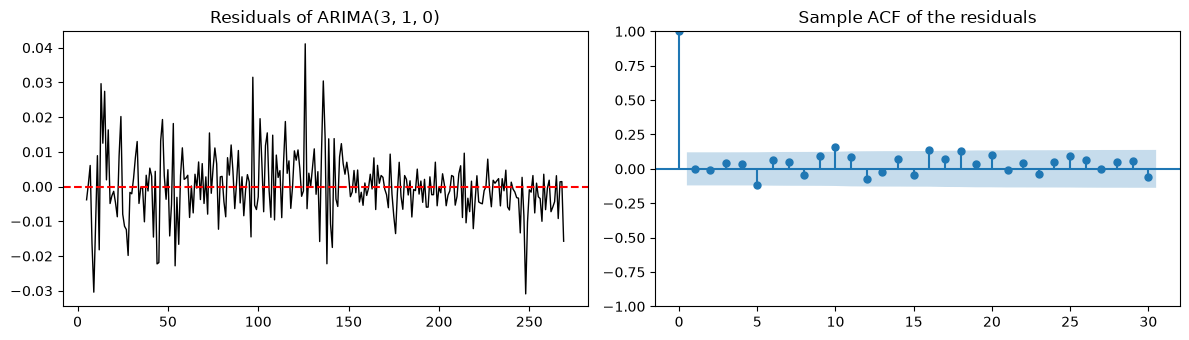

In [127]:
resid = arimamod.resid[4:] #we are dropping the first four residuals.

fig, ax = plt.subplots(1, 2, figsize = (12, 3.5))
ax[0].plot(tme_train[4:], resid, color = 'black', linewidth = 1)
ax[0].axhline(0, color = 'red', linestyle = '--')
ax[0].set_title('Residuals of ARIMA(3, 1, 0)')
plot_acf(resid, lags = 30, ax = ax[1])
ax[1].set_title("Sample ACF of the residuals")
plt.tight_layout()
plt.show()

The residual ACF has no large autocorrelations. A few values (at lag 5 and near lags 9-11, i.e., around two and a half years) sit at the edge of the band; the ones near lags 9-11 were already visible in the ACF of the growth rates. A low-order ARIMA model cannot capture these and we accept the model.

## Forecasting with ARIMA

The `get_prediction` method gives the forecasts (of log GDP itself, not of the differences), their standard errors, and prediction intervals.

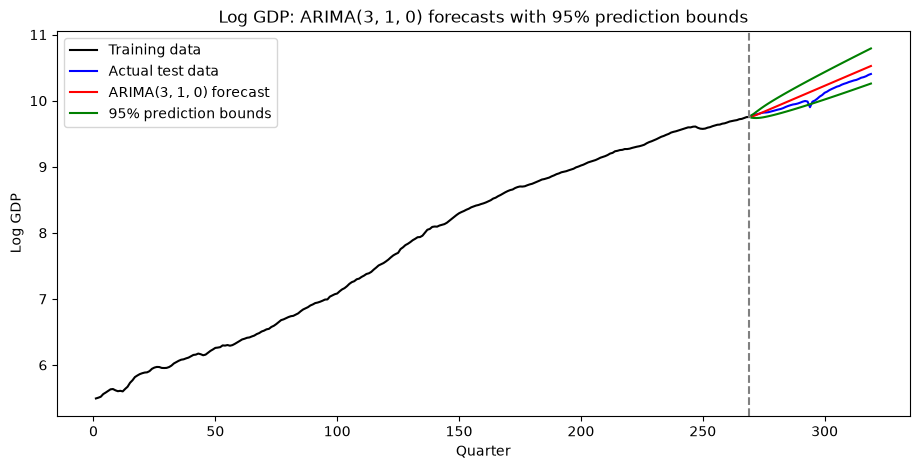

Test MSE (log scale) of ARIMA(3, 1, 0) with drift: 0.00980999805728587


In [128]:
n_train = len(ylog_train)
k = n_test
fcast = arimamod.get_prediction(start = n_train, end = n_train + k - 1)
fcast_mean = np.asarray(fcast.predicted_mean)
fcast_se = np.asarray(fcast.se_mean)
alpha = 0.05
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = fcast_mean - z_alpha_half * fcast_se
predupper = fcast_mean + z_alpha_half * fcast_se

plt.figure(figsize = (11, 5))
plt.plot(tme_train, ylog_train, color = 'black', label = 'Training data')
plt.plot(tme_test, ylog_test, color = 'blue', label = 'Actual test data')
plt.plot(tme_test, fcast_mean, color = 'red', label = 'ARIMA(3, 1, 0) forecast')
plt.plot(tme_test, predlower, color = 'green', label = '95% prediction bounds')
plt.plot(tme_test, predupper, color = 'green')
plt.axvline(x = n_train, color = 'gray', linestyle = '--')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('Log GDP: ARIMA(3, 1, 0) forecasts with 95% prediction bounds')
plt.legend()
plt.show()

mse_arima = np.mean((ylog_test - fcast_mean)**2)
print("Test MSE (log scale) of ARIMA(3, 1, 0) with drift:", mse_arima)

The forecast is a straight line (with slope equal to the estimated drift, 1.58% per quarter) plus a short-run adjustment in the first few quarters, and the prediction intervals keep widening with the horizon. 

Let us compare with the AR(4) model (fit to the log-GDP data directly, and not to the differences) from Lecture 19. We compute the test MSE over the whole test period and also over the first 4 and first 8 quarters of the test period.

In [129]:
armod4 = AutoReg(ylog_train, lags = 4).fit()
fcast_mean_ar4 = np.asarray(armod4.get_prediction(start = n_train, end = n_train + k - 1).predicted_mean)

def mse_by_horizon(fc):
    err2 = (ylog_test - fc)**2
    return [np.mean(err2[:4]), np.mean(err2[:8]), np.mean(err2)]

comparison = pd.DataFrame({'Model': ['ARIMA(3, 1, 0) with drift', 'AR(4) in levels (Lecture 19)'],
                           'MSE first 4 quarters': [mse_by_horizon(fcast_mean)[0], mse_by_horizon(fcast_mean_ar4)[0]],
                           'MSE first 8 quarters': [mse_by_horizon(fcast_mean)[1], mse_by_horizon(fcast_mean_ar4)[1]],
                           'MSE all 50 quarters': [mse_by_horizon(fcast_mean)[2], mse_by_horizon(fcast_mean_ar4)[2]]})
print(comparison.to_string(index = False))
print("\nAverage growth rate per quarter: training data", np.round(np.mean(ylogdiff_train), 4),
      "; test period", np.round((ylog_test[-1] - ylog_train[-1]) / n_test, 4))

                       Model  MSE first 4 quarters  MSE first 8 quarters  MSE all 50 quarters
   ARIMA(3, 1, 0) with drift              0.000106              0.000304             0.009810
AR(4) in levels (Lecture 19)              0.000207              0.000150             0.001558

Average growth rate per quarter: training data 0.0159 ; test period 0.013


The ARIMA forecasts are better for the first few quarters but worse over the whole 50-quarter test period. The reason is the drift: the long-range ARIMA forecast grows at the average growth rate of the training period (1947-2013), which is 1.6% per quarter, while GDP actually grew at 1.3% per quarter during the test period (2014-2026), so the ARIMA forecasts overshoot. The AR(4) model in levels (whose root of modulus 1.0016 makes it essentially an ARIMA(3, 1, 0) model in disguise) extrapolated a lower growth rate and happened to land closer. The lesson: for a trending series, the orders $p$ and $q$ matter for short-range forecasts, while long-range forecasts are dominated by the assumed trend, which no choice of $p$ and $q$ can fix.

# Seasonal ARIMA models

## The $CO_2$ data

The following data is the monthly mean atmospheric $CO_2$ concentration (in parts per million) measured at the Mauna Loa Observatory in Hawaii, from March 1958 to September 2026 (823 months). The data is collected by NOAA (https://gml.noaa.gov/ccgg/trends/data.html). The data has a clear upward trend and a clear seasonal pattern: $CO_2$ rises during the winter and falls during the summer (when plants in the Northern Hemisphere absorb $CO_2$). We hold out the last 36 months (3 years) as test data.

      Date     CO2  CO2_deseasonalized
0  1958-03  315.71              314.44
1  1958-04  317.45              315.16
2  1958-05  317.51              314.69
3  1958-06  317.27              315.15
4  1958-07  315.87              315.20


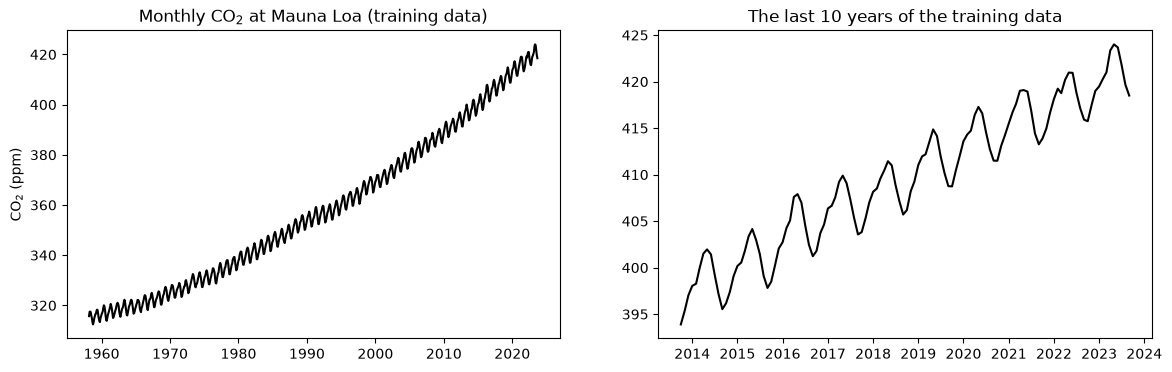

In [130]:
co2 = pd.read_csv("CO2_MaunaLoa_Nov2026.csv")
print(co2.head())
dates = pd.to_datetime(co2['Date'])
y = co2['CO2'].to_numpy()
n = len(y)
n_test = 36
n_train = n - n_test
y_train = y[:n_train]
y_test = y[n_train:]
dates_train = dates[:n_train]
dates_test = dates[n_train:]

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
ax[0].plot(dates_train, y_train, color = 'black')
ax[0].set_title('Monthly CO$_2$ at Mauna Loa (training data)')
ax[0].set_ylabel('CO$_2$ (ppm)')
ax[1].plot(dates_train[-120:], y_train[-120:], color = 'black')
ax[1].set_title('The last 10 years of the training data')
plt.show()

## Seasonal and ordinary differencing

The sample ACF of the raw series decays very slowly (as for log GDP), so differencing is needed. The two options are $y_t - y_{t-1}$ and $y_t - y_{t-12}$. Let us first look at the first differences $\nabla y_t = y_t - y_{t-1}$ (the month-to-month changes).

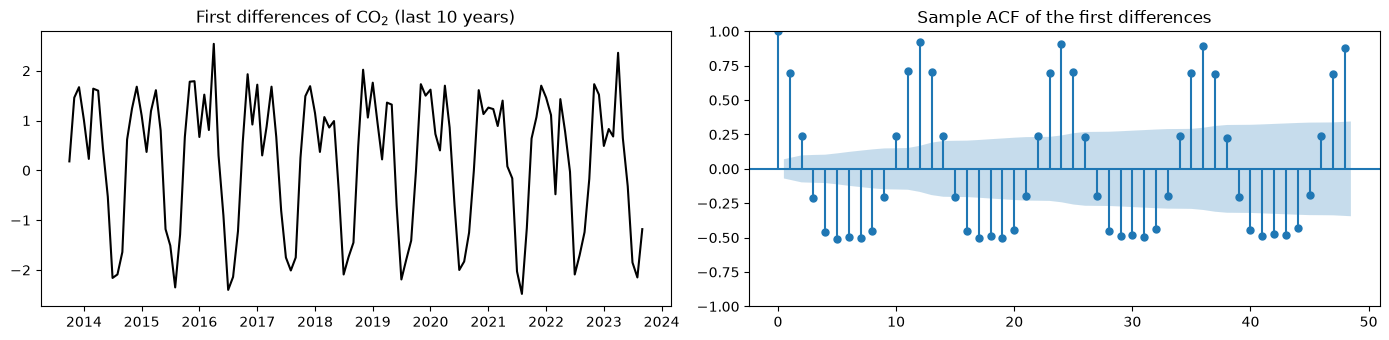

Sample ACF of the first differences at lags 12, 24, 36, 48: [0.923 0.91  0.892 0.876]


In [131]:
ydiff_train = np.diff(y_train)

fig, ax = plt.subplots(1, 2, figsize = (14, 3.5))
ax[0].plot(dates_train[1:][-120:], ydiff_train[-120:], color = 'black')
ax[0].set_title('First differences of CO$_2$ (last 10 years)')
plot_acf(ydiff_train, lags = 48, ax = ax[1])
ax[1].set_title('Sample ACF of the first differences')
plt.tight_layout()
plt.show()
print("Sample ACF of the first differences at lags 12, 24, 36, 48:", np.round(acf(ydiff_train, nlags = 48)[[12, 24, 36, 48]], 3))

The month-to-month changes still have a strong seasonal pattern that repeats every year: the sample ACF has large spikes at lags 12, 24, 36, 48 (0.92, 0.91, 0.89, 0.88) which decay very slowly. 

Next we look at the seasonal differences $y_t - y_{t-12}$. The seasonal difference $y_t - y_{t-12}$ is the change from the same month of the previous year (the annual increase in CO$_2$).

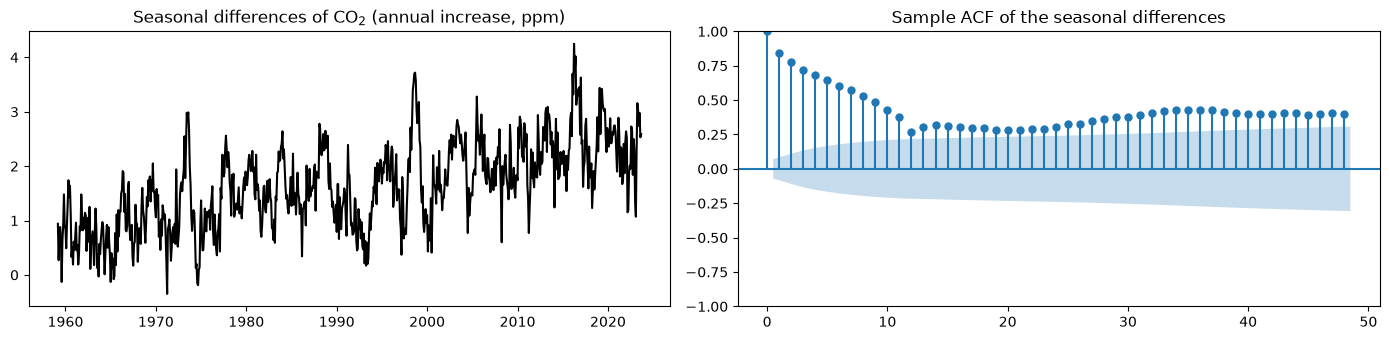

In [132]:
s = 12
ydiff12_train = y_train[s:] - y_train[:-s]

fig, ax = plt.subplots(1, 2, figsize = (14, 3.5))
ax[0].plot(dates_train[s:], ydiff12_train, color = 'black')
ax[0].set_title('Seasonal differences of CO$_2$ (annual increase, ppm)')
plot_acf(ydiff12_train, lags = 48, ax = ax[1])
ax[1].set_title('Sample ACF of the seasonal differences')
plt.tight_layout()
plt.show()

The seasonal pattern is gone. But the annual increase wanders: it was below 1 ppm per year in the 1960s and is about 2.5 ppm per year now, and its sample ACF decays slowly. So we also take an ordinary difference, i.e., $d = 1$. The series $\nabla \nabla_{12} y_t = y_t - y_{t-1} - y_{t-12} + y_{t-13}$ fluctuates around zero with no trend and no seasonal pattern.

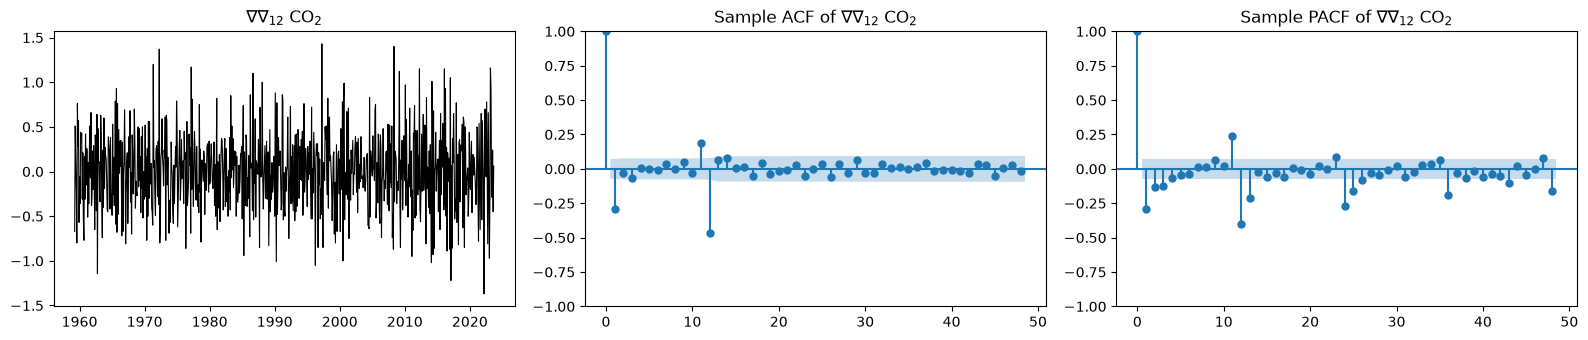

Sample ACF  at lags 1, 2, 3, 11, 12, 13, 24, 36: [-0.291 -0.033 -0.065  0.191 -0.47   0.066 -0.003  0.012]
Sample PACF at lags 1, 2, 3, 11, 12, 13, 24, 36: [-0.291 -0.128 -0.126  0.237 -0.4   -0.212 -0.272 -0.192]


In [133]:
ydd_train = np.diff(ydiff12_train) # first difference of the seasonal differences

fig, ax = plt.subplots(1, 3, figsize = (16, 3.5))
ax[0].plot(dates_train[s+1:], ydd_train, color = 'black', linewidth = 0.8)
ax[0].set_title(r'$\nabla \nabla_{12}$ CO$_2$')
plot_acf(ydd_train, lags = 48, ax = ax[1])
ax[1].set_title(r'Sample ACF of $\nabla \nabla_{12}$ CO$_2$')
plot_pacf(ydd_train, lags = 48, ax = ax[2], method = 'ols')
ax[2].set_title(r'Sample PACF of $\nabla \nabla_{12}$ CO$_2$')
plt.tight_layout()
plt.show()

acf_dd = acf(ydd_train, nlags = 36)
pacf_dd = pacf(ydd_train, nlags = 36, method = 'ols')
print("Sample ACF  at lags 1, 2, 3, 11, 12, 13, 24, 36:", np.round(acf_dd[[1, 2, 3, 11, 12, 13, 24, 36]], 3))
print("Sample PACF at lags 1, 2, 3, 11, 12, 13, 24, 36:", np.round(pacf_dd[[1, 2, 3, 11, 12, 13, 24, 36]], 3))

## Choosing $p, q, P, Q$ by AIC/BIC (with $d = D = 1$ fixed)

We now fit all models with $p, q \in \{0, 1, 2\}$ and $P, Q \in \{0, 1\}$, keeping $d = D = 1$ fixed, and compare their AIC and BIC values (36 models; this takes a few seconds).

In [134]:
results = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                model = ARIMA(y_train, order = (p, 1, q), seasonal_order = (P, 1, Q, 12)).fit()
                results.append({'p': p, 'd': 1, 'q': q, 'P': P, 'D': 1, 'Q': Q, 'AIC': model.aic, 'BIC': model.bic})
results_df = pd.DataFrame(results)

print("Models sorted by AIC (best first):")
print(results_df.sort_values('AIC').head(6).to_string(index = False))
print("\nModels sorted by BIC (best first):")
print(results_df.sort_values('BIC').head(6).to_string(index = False))

Models sorted by AIC (best first):
 p  d  q  P  D  Q        AIC        BIC
 1  1  1  0  1  1 424.674489 443.280776
 2  1  1  0  1  1 425.552427 448.810287
 1  1  2  0  1  1 425.888984 449.146844
 0  1  2  0  1  1 426.244975 444.851263
 1  1  1  1  1  1 426.672866 449.930726
 2  1  2  0  1  1 426.917381 454.826812

Models sorted by BIC (best first):
 p  d  q  P  D  Q        AIC        BIC
 0  1  1  0  1  1 428.564773 442.519489
 1  1  1  0  1  1 424.674489 443.280776
 0  1  2  0  1  1 426.244975 444.851263
 2  1  1  0  1  1 425.552427 448.810287
 1  1  2  0  1  1 425.888984 449.146844
 0  1  1  1  1  1 430.562768 449.169055


BIC picks the  model ARIMA(0, 1, 1)$\times$(0, 1, 1)$_{12}$ while AIC picks ARIMA(1, 1, 1)$\times$(0, 1, 1)$_{12}$, which has one extra AR coefficient. We fit both these models to the observed data as follows. 

In [135]:
co2_bic = ARIMA(y_train, order = (0, 1, 1), seasonal_order = (0, 1, 1, 12)).fit()
print(co2_bic.summary())

                                    SARIMAX Results                                     
Dep. Variable:                                y   No. Observations:                  787
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -211.282
Date:                          Wed, 11 Nov 2026   AIC                            428.565
Time:                                  21:22:10   BIC                            442.519
Sample:                                       0   HQIC                           433.934
                                          - 787                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3842      0.032    -12.037      0.000      -0.447      -0.322
ma.S.L12      -0.8648      0.020    -42.761      0.

In [136]:
co2_aic = ARIMA(y_train, order = (1, 1, 1), seasonal_order = (0, 1, 1, 12)).fit()
print(co2_aic.summary())

                                    SARIMAX Results                                     
Dep. Variable:                                y   No. Observations:                  787
Model:             ARIMA(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -208.337
Date:                          Wed, 11 Nov 2026   AIC                            424.674
Time:                                  21:22:10   BIC                            443.281
Sample:                                       0   HQIC                           431.833
                                          - 787                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2354      0.080      2.925      0.003       0.078       0.393
ma.L1         -0.5912      0.067     -8.869      0.

Next we obtain forecasts using these two models. 

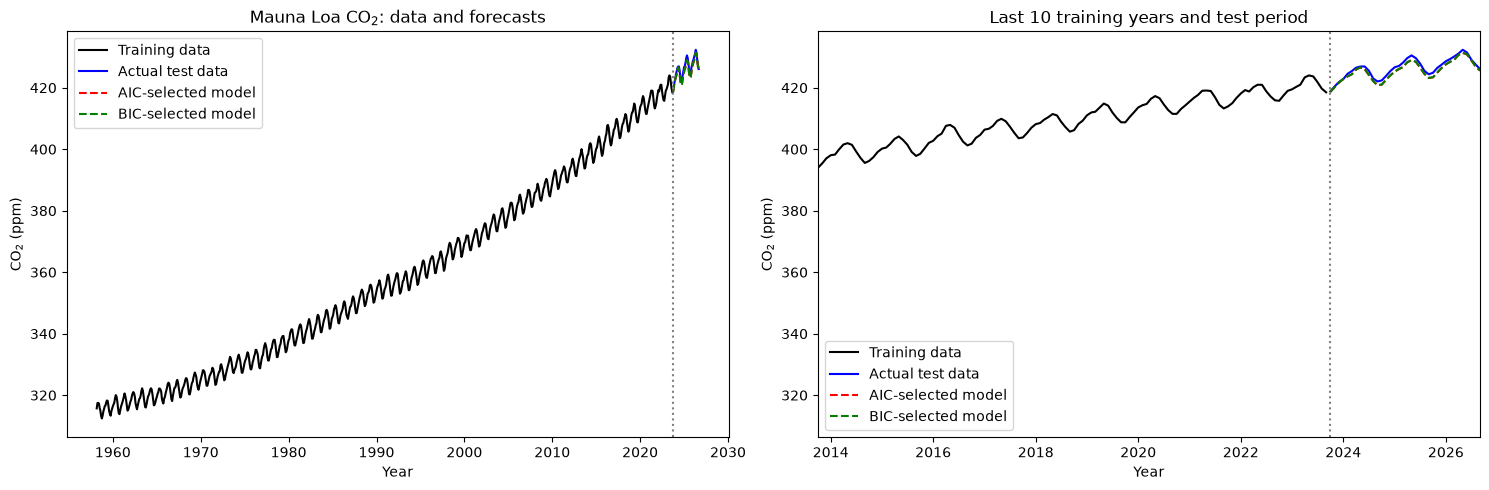

In [138]:
# Predictions for the test period
fcast_aic = co2_aic.get_prediction(start = n_train, end = n_train + n_test - 1)
fcast_bic = co2_bic.get_prediction(start = n_train, end = n_train + n_test - 1)

pred_aic = np.asarray(fcast_aic.predicted_mean)
pred_bic = np.asarray(fcast_bic.predicted_mean)

# Full series and a closer view of the recent data
fig, axes = plt.subplots(1, 2, figsize = (15, 5))

for ax in axes:
    ax.plot(dates_train, y_train, color = 'black', label = 'Training data')
    ax.plot(dates_test, y_test, color = 'blue', label = 'Actual test data')
    ax.plot(dates_test, pred_aic, color = 'red', linestyle = '--',
            label = 'AIC-selected model')
    ax.plot(dates_test, pred_bic, color = 'green', linestyle = '--',
            label = 'BIC-selected model')
    ax.axvline(dates_test.iloc[0], color = 'gray', linestyle = ':')
    ax.set_xlabel('Year')
    ax.set_ylabel('CO$_2$ (ppm)')
    ax.legend()

axes[0].set_title('Mauna Loa CO$_2$: data and forecasts')
axes[1].set_xlim(dates_train.iloc[max(0, n_train - 120)], dates_test.iloc[-1])
axes[1].set_title('Last 10 training years and test period')

plt.tight_layout()
plt.show()

Let us check the residuals corresponding to the fitted models. Again, the initial residuals are not meaningful so we will drop them. Specifically, with $d = 1$ and $D = 1$, the first $1 + 12 = 13$ residuals are not meaningful (the corresponding observations cannot be predicted from the past) and we drop them.

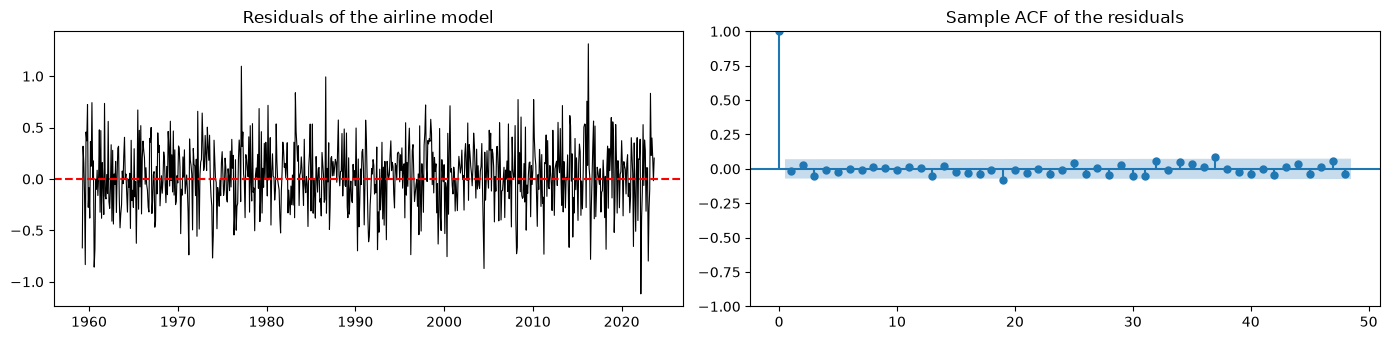

In [139]:
resid = co2_aic.resid[13:]

fig, ax = plt.subplots(1, 2, figsize = (14, 3.5))
ax[0].plot(dates_train[13:], resid, color = 'black', linewidth = 0.8)
ax[0].axhline(0, color = 'red', linestyle = '--')
ax[0].set_title('Residuals of the airline model')
plot_acf(resid, lags = 48, ax = ax[1])
ax[1].set_title('Sample ACF of the residuals')
plt.tight_layout()
plt.show()


## Airline passengers dataset

We repeat the prediction analysis for the airline passengers dataset. This is a popular dataset for evaluating prediction accuracy of various models. It contains monthly data on the number of international airline passengers (in thousands) from January 1949 to December 1960. 

          time  value
0  1949.000000    112
1  1949.083333    118
2  1949.166667    132
3  1949.250000    129
4  1949.333333    121


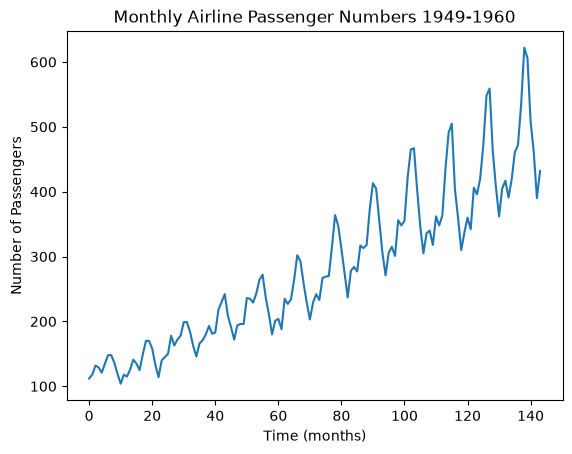

In [140]:
data = sm.datasets.get_rdataset("AirPassengers").data
print(data.head())
y = data['value'].to_numpy()
plt.plot(y)
plt.xlabel('Time (months)')
plt.ylabel('Number of Passengers')
plt.title('Monthly Airline Passenger Numbers 1949-1960')
plt.show()

As usual, we fit models to logarithms. 

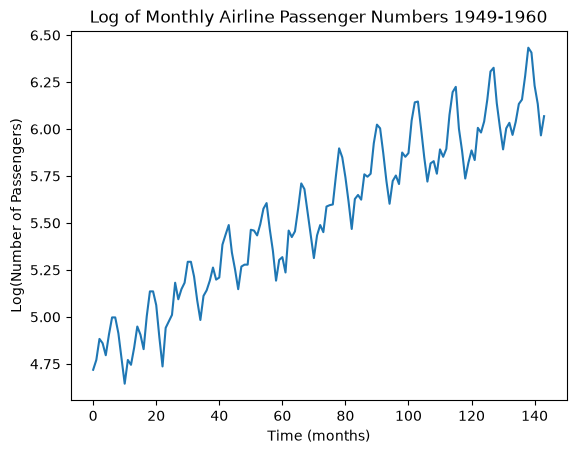

In [144]:
ylog = np.log(y)
plt.plot(ylog)
plt.xlabel('Time (months)')
plt.ylabel('Log(Number of Passengers)')
plt.title('Log of Monthly Airline Passenger Numbers 1949-1960')
plt.show()

We fit models to the double differences $\nabla \nabla_{12} y_t$. 

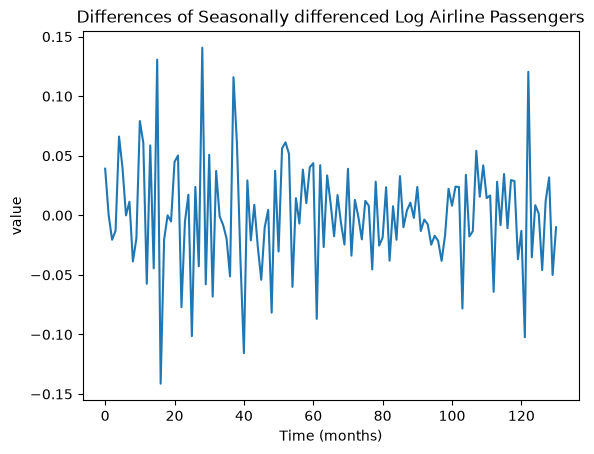

In [146]:
#Seasonal differencing: y_t - y_{t-12}
ylogdiff12 = ylog[12:] - ylog[:-12]
#Regular differences of the seasonal differences. 
ylog2d = np.diff(ylogdiff12)
plt.plot(ylog2d)
plt.xlabel('Time (months)')
plt.ylabel('value')
plt.title('Differences of Seasonally differenced Log Airline Passengers')
plt.show()

We now search over a bunch of $p, q, P, Q$ values to find the best model via AIC/BIC.

In [147]:
results = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                model = ARIMA(ylog, order = (p, 1, q), seasonal_order = (P, 1, Q, 12)).fit()
                results.append({'p': p, 'd': 1, 'q': q, 'P': P, 'D': 1, 'Q': Q, 'AIC': model.aic, 'BIC': model.bic})
results_df = pd.DataFrame(results)

print("Models sorted by AIC (best first):")
print(results_df.sort_values('AIC').head(6).to_string(index = False))
print("\nModels sorted by BIC (best first):")
print(results_df.sort_values('BIC').head(6).to_string(index = False))

Models sorted by AIC (best first):
 p  d  q  P  D  Q         AIC         BIC
 0  1  1  0  1  1 -483.392918 -474.767326
 2  1  1  0  1  1 -482.260604 -467.884617
 0  1  1  1  1  1 -481.906210 -470.405420
 1  1  1  0  1  1 -481.892939 -470.392150
 0  1  2  0  1  1 -481.610058 -470.109269
 1  1  0  0  1  1 -481.483823 -472.858231

Models sorted by BIC (best first):
 p  d  q  P  D  Q         AIC         BIC
 0  1  1  0  1  1 -483.392918 -474.767326
 1  1  0  0  1  1 -481.483823 -472.858231
 0  1  1  1  1  1 -481.906210 -470.405420
 1  1  1  0  1  1 -481.892939 -470.392150
 0  1  2  0  1  1 -481.610058 -470.109269
 0  1  1  1  1  0 -477.398538 -468.772946


The best model, according to both AIC and BIC, is ARIMA$(0, 1, 1) \times (0, 1, 1)_{12}$. 

In [148]:
airline_aic = ARIMA(ylog, order = (0, 1, 1), seasonal_order = (0, 1, 1, 12)).fit()
print(airline_aic.summary())

                                    SARIMAX Results                                     
Dep. Variable:                                y   No. Observations:                  144
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                          Wed, 11 Nov 2026   AIC                           -483.393
Time:                                  21:30:23   BIC                           -474.767
Sample:                                       0   HQIC                          -479.888
                                          - 144                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4017      0.073     -5.505      0.000      -0.545      -0.259
ma.S.L12      -0.5572      0.096     -5.791      0.

Future predictions by this SARIMA model are obtained as follows. 

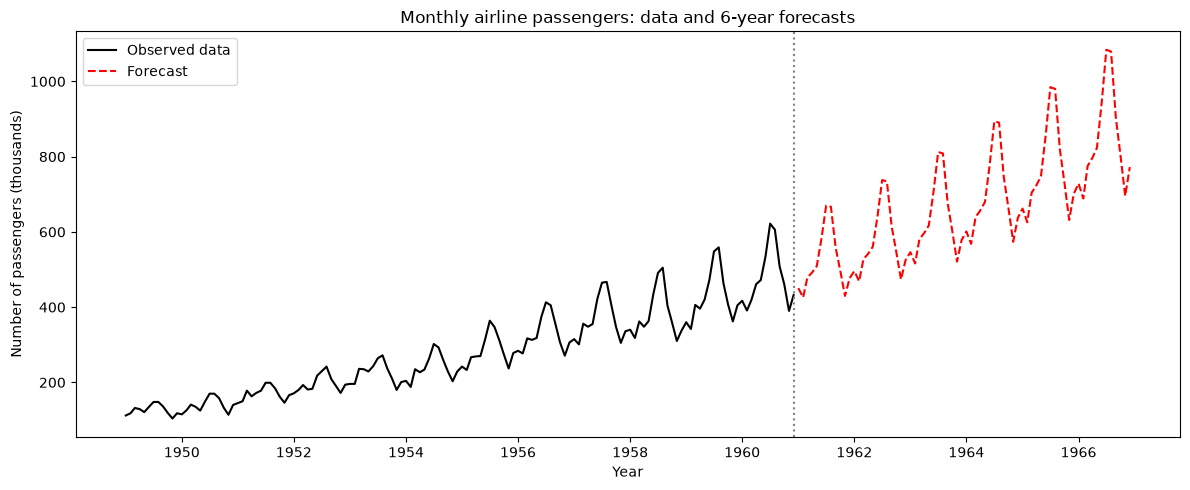

In [149]:
# Predict future log passenger numbers
n = len(ylog)
k = 72
fcast = airline_aic.get_prediction(start = n, end = n + k - 1)

# Convert forecasts back to the original scale
pred = np.exp(np.asarray(fcast.predicted_mean))

dates = pd.date_range(start = '1949-01-01', periods = n + k, freq = 'MS')

plt.figure(figsize = (12, 5))
plt.plot(dates[:n], y, color = 'black', label = 'Observed data')
plt.plot(dates[n:], pred, color = 'red', linestyle = '--',
         label = 'Forecast')
plt.axvline(dates[n - 1], color = 'gray', linestyle = ':')

plt.xlabel('Year')
plt.ylabel('Number of passengers (thousands)')
plt.title('Monthly airline passengers: data and 6-year forecasts')
plt.legend()
plt.tight_layout()
plt.show()